In [ ]:
import pandas as pd
df = pd.read_csv('FAANG - FAANG.csv.csv')
df

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23055 entries, 0 to 23054
Data columns (total 41 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Company                                23055 non-null  str    
 1   Ticker                                 23055 non-null  str    
 2   Date                                   23055 non-null  str    
 3   Open                                   23055 non-null  float64
 4   High                                   23055 non-null  float64
 5   Low                                    23055 non-null  float64
 6   Close                                  23055 non-null  float64
 7   Adj Close                              23055 non-null  float64
 8   Volume                                 23055 non-null  int64  
 9   Market Cap                             23055 non-null  float64
 10  PE Ratio                               23055 non-null  float64
 11  Beta         

In [3]:
empty_colmns = df.columns[df.isnull().all()].tolist()
df = df.drop(columns=empty_colmns)

In [4]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['DayOfWeek'] = df['Date'].dt.day_of_week
df = df.drop(columns=['Date'])

In [5]:
missval_cols = df.isnull().sum().sort_values(ascending=False).head(5).index.tolist()
missval_cols = list(map(lambda x:f'{x}',missval_cols))
for i in missval_cols:
    print(f"The dtype of {i} is : {df[i].dtype}")
    print("**********")

The dtype of Annual Dividend Rate is : float64
**********
The dtype of Dividends Paid is : float64
**********
The dtype of Dividend Yield is : float64
**********
The dtype of Beta (5Y) is : float64
**********
The dtype of Beta is : float64
**********


Skewness value for Annual Dividend Rate column: 1.1096913689210595
************
Skewness value for Dividends Paid column: 1.1096913689210595
************
Skewness value for Dividend Yield column: -0.46767037387338817
************
Skewness value for Beta (5Y) column: -0.44072974037525753
************
Skewness value for Beta column: -0.44072974037525753
************


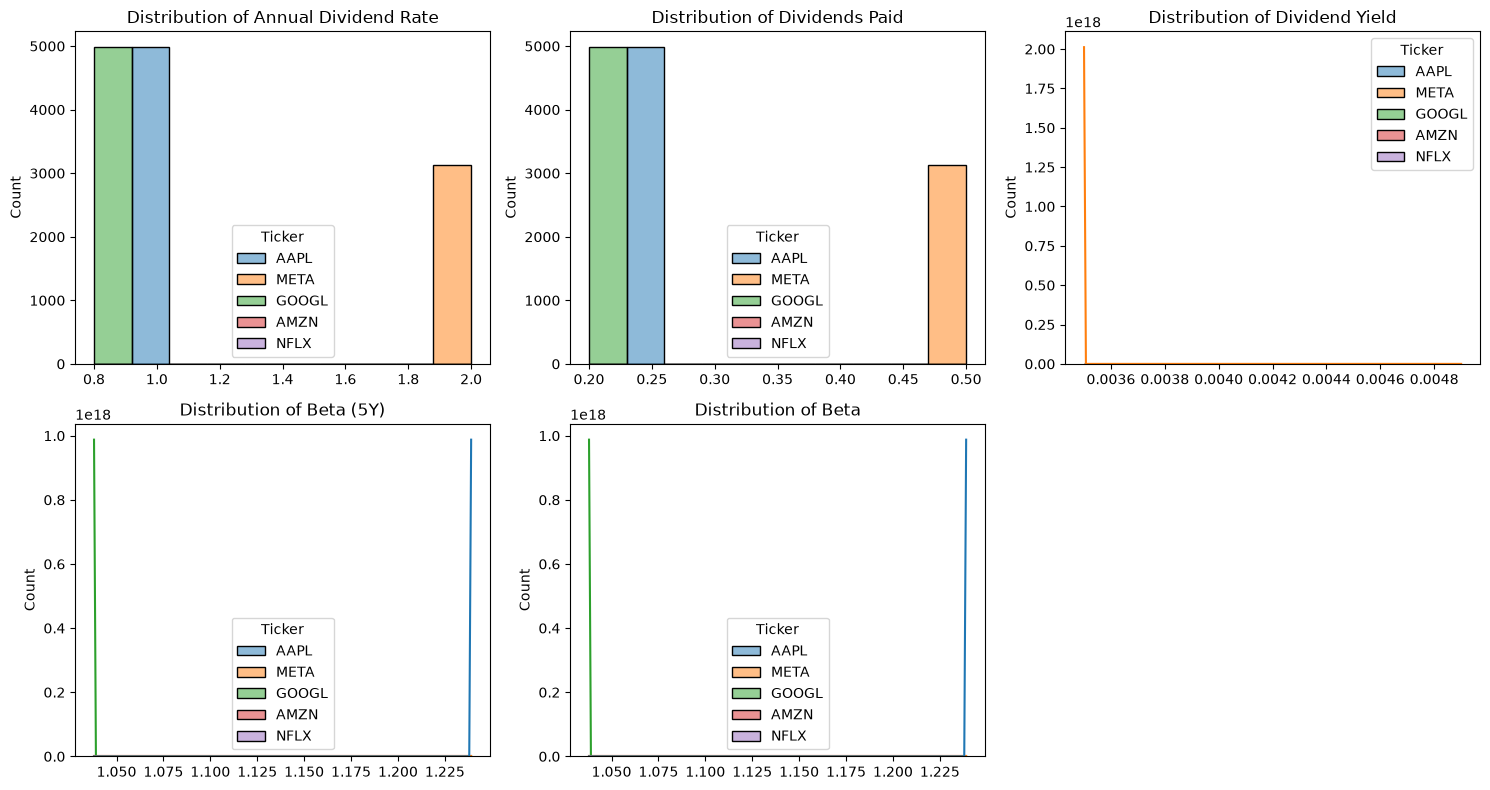

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes = plt.subplots(nrows = 2, ncols = 3, figsize = (15,8))
for i,col in enumerate(missval_cols):
    print(f"Skewness value for {col} column:", df[col].skew())
    print("************")
    row = i // 3
    cols = i % 3
    sns.histplot(data=df, x=col, kde=True, ax=axes[row,cols], color='teal', bins=10, hue='Ticker')
    axes[row,cols].set_title(f'Distribution of {col}', fontsize = 12)

    axes[row,cols].set_xlabel('')
axes[1, 2].set_visible(False)
plt.tight_layout()
plt.show()

    


In [7]:
print(df.groupby('Ticker')['Annual Dividend Rate'].value_counts().reset_index())
print("*******")
print(df.groupby('Ticker')['Dividends Paid'].value_counts().reset_index())
print("*******")
print(df.groupby('Ticker')['Dividend Yield'].value_counts().reset_index())
print("*******")
print(df.groupby('Ticker')['Beta (5Y)'].value_counts().reset_index())
print("*******")
print(df.groupby('Ticker')['Beta'].value_counts().reset_index())

  Ticker  Annual Dividend Rate  count
0   AAPL                   1.0   4983
1  GOOGL                   0.8   4983
2   META                   2.0   3125
*******
  Ticker  Dividends Paid  count
0   AAPL            0.25   4983
1  GOOGL            0.20   4983
2   META            0.50   3125
*******
  Ticker  Dividend Yield  count
0   AAPL          0.0043   4983
1  GOOGL          0.0049   4983
2   META          0.0035   3125
*******
  Ticker  Beta (5Y)  count
0   AAPL      1.239   4983
1   AMZN      1.147   4982
2  GOOGL      1.038   4983
3   META      1.216   3125
*******
  Ticker   Beta  count
0   AAPL  1.239   4983
1   AMZN  1.147   4982
2  GOOGL  1.038   4983
3   META  1.216   3125


In [8]:
print("Beta (5Y) Missing Values :", df[df['Beta (5Y)'].isna()]['Ticker'].unique())
print(df['Beta (5Y)'].isnull().groupby(df['Ticker']).sum())
print("******")
print("Beta Missing Values :", df[df['Beta'].isna()]['Ticker'].unique())
print(df['Beta'].isnull().groupby(df['Ticker']).sum())
print("******")

Beta (5Y) Missing Values : <ArrowStringArray>
['NFLX']
Length: 1, dtype: str
Ticker
AAPL        0
AMZN        0
GOOGL       0
META        0
NFLX     4982
Name: Beta (5Y), dtype: int64
******
Beta Missing Values : <ArrowStringArray>
['NFLX']
Length: 1, dtype: str
Ticker
AAPL        0
AMZN        0
GOOGL       0
META        0
NFLX     4982
Name: Beta, dtype: int64
******


In [9]:
print("Annual Dividend Rate Missing Values :", df[df['Annual Dividend Rate'].isna()]['Ticker'].unique())
print(df['Annual Dividend Rate'].isnull().groupby(df['Ticker']).sum())
print("******")

Annual Dividend Rate Missing Values : <ArrowStringArray>
['AMZN', 'NFLX']
Length: 2, dtype: str
Ticker
AAPL        0
AMZN     4982
GOOGL       0
META        0
NFLX     4982
Name: Annual Dividend Rate, dtype: int64
******


In [10]:
print("Dividends Paid Missing Values :", df[df['Dividends Paid'].isna()]['Ticker'].unique())
print(df['Dividends Paid'].isnull().groupby(df['Ticker']).sum())
print("******")
print("Dividend Yield Missing Values :", df[df['Dividend Yield'].isna()]['Ticker'].unique())
print(df['Dividend Yield'].isnull().groupby(df['Ticker']).sum())
print("******")

Dividends Paid Missing Values : <ArrowStringArray>
['AMZN', 'NFLX']
Length: 2, dtype: str
Ticker
AAPL        0
AMZN     4982
GOOGL       0
META        0
NFLX     4982
Name: Dividends Paid, dtype: int64
******
Dividend Yield Missing Values : <ArrowStringArray>
['AMZN', 'NFLX']
Length: 2, dtype: str
Ticker
AAPL        0
AMZN     4982
GOOGL       0
META        0
NFLX     4982
Name: Dividend Yield, dtype: int64
******


In [11]:
#  AMZN & NFLX - Filling with 0:
df['Annual Dividend Rate'] = df['Annual Dividend Rate'].fillna(0)
df['Dividends Paid'] = df['Dividends Paid'].fillna(0)
df['Dividend Yield'] = df['Dividend Yield'].fillna(0)


# Filling with Mean(): 
df['Beta (5Y)'] = df['Beta (5Y)'].fillna(df['Beta (5Y)'].mean())
df['Beta'] = df['Beta'].fillna(df['Beta'].mean())
#print(df[['Annual Dividend Rate', 'Dividends Paid', 'Dividend Yield', 'Beta (5Y)', 'Beta']].isnull().sum())
print(df.isnull().sum().sort_values(ascending= False).head(3))

Company    0
Ticker     0
Open       0
dtype: int64


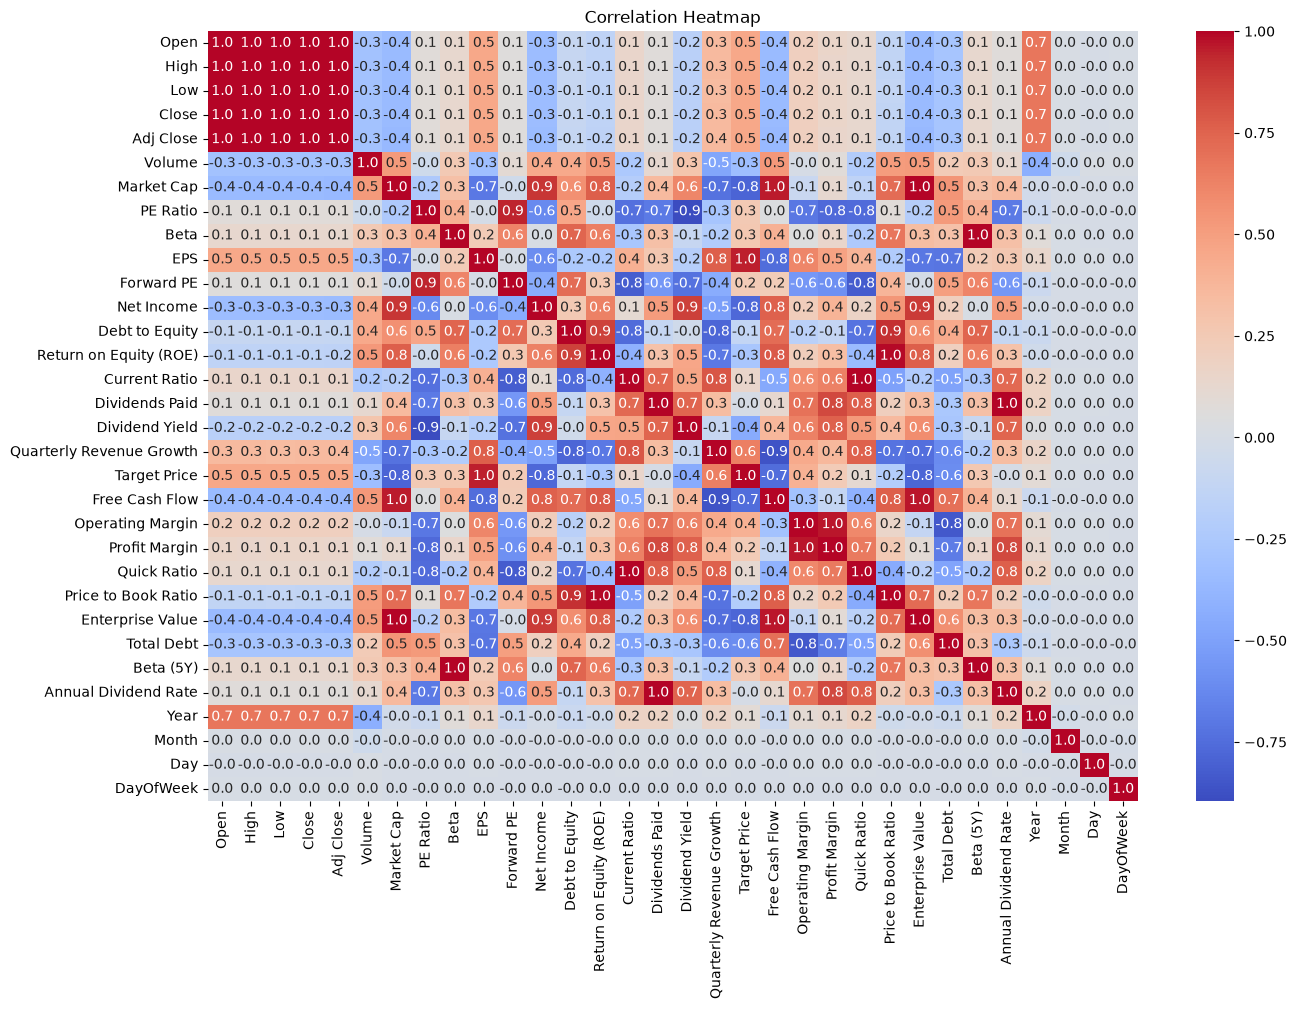

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
numerical_cols = df.select_dtypes(include=['Float64','int64','int32']).columns
# Correlation matrix edukkura code
correlation_matrix = df[numerical_cols].corr()

# Theliva Heatmap plot pandrom
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',fmt='.1f')
plt.title('Correlation Heatmap')
plt.show()

In [13]:
df.select_dtypes(include=['str','object'])

,Company,Ticker,Analyst Recommendation
0,Apple,AAPL,buy
1,Apple,AAPL,buy
2,Apple,AAPL,buy
3,Apple,AAPL,buy
4,Apple,AAPL,buy
...,...,...,...
23050,Netflix,NFLX,buy
23051,Netflix,NFLX,buy
23052,Netflix,NFLX,buy
23053,Netflix,NFLX,buy


In [14]:
cols_to_drop = ['Adj Close', 'Enterprise Value', 'Company']
df = df.drop(columns=cols_to_drop, errors='ignore')
# Encoding:

df_encoded = pd.get_dummies(df, columns=['Ticker', 'Analyst Recommendation'], drop_first=True, dtype=int)
# Splitting:

from sklearn.model_selection import train_test_split

# Splitting Target & Features:
X = df_encoded.drop(columns=['Close'])
y = df_encoded['Close']

# Put shuffle = False bcz this is time series data:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (18444, 33)
Test shape: (4611, 33)


In [15]:
# Scalling:

from sklearn.preprocessing import StandardScaler
import pandas as pd

scaler = StandardScaler()

# Train data mela fit_transform pandrom
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

# Test data mela transform mattum thaan pandrom (NO fitting here)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 1. Model Initialize & Training:
print("Training the Random Forest model...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# 2. Predict by Test Data:
y_pred = rf_model.predict(X_test_scaled)

# 3. Evaluate how the model perform:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("-" * 30)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")
print("-" * 30)

Training the Random Forest model...
------------------------------
Mean Absolute Error (MAE): 4.4173
Root Mean Squared Error (RMSE): 15.5498
R2 Score: 0.9940
------------------------------


In [ ]:
import mlflow
import mlflow.sklearn


mlflow.set_experiment("FAANG_Stock_Prediction")

with mlflow.start_run():
    
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("r2", r2)
    
    mlflow.log_param("n_estimators", 100)
    mlflow.log_param("random_state", 42)
    
    
    mlflow.sklearn.log_model(
      rf_model, 
      "best_rf_model",
      serialization_format="cloudpickle"
    )
    
    print("Model and metrics are successfully logged in MLflow!")

2026/10/13 16:04:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/13 16:04:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Model and metrics are successfully logged in MLflow!


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import mlflow


ui_features = ['Open', 'High', 'Low', 'Volume', 'Ticker_AMZN', 'Ticker_GOOGL', 'Ticker_META', 'Ticker_NFLX']
X_train_ui = X_train[ui_features]
X_test_ui = X_test[ui_features]


pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf_model', RandomForestRegressor(n_estimators=100, random_state=42))
])

print("Training lightweight UI model...")
pipeline.fit(X_train_ui, y_train)

with mlflow.start_run():
    
    mlflow.sklearn.log_model(pipeline, "ui_ready_rf_model", serialization_format="cloudpickle")
    print("UI Ready model has loaded in MLflow!")

Training lightweight UI model...


2026/10/13 16:05:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/13 16:05:38 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


UI Ready model MLflow-la theliva save aagiduchu!
